# 02 — Clustering: K-means pallor groups (Unit V)

Inputs: `outputs/features_cp_anemic.csv` (eye primary set, 220 children with Hb) and the Ghana palm / nail feature CSVs
(folder labels). Library code: `src/netra/clustering.py`; K-means and bisecting K-means also run with our NumPy versions
in `src/netra/scratch/kmeans.py`. Figures go to `outputs/figures/clustering/`, results to
`outputs/results/clustering.json`, the eye cluster model to `outputs/models/clusters_eye.joblib`.

**What this is and is not.** Clustering is unsupervised: K-means sees only the 14 standardised `MODEL_FEATURES`.
Hb severity bands (normal / mild / moderate / severe, WHO 6–59 mo) are used *only afterwards* as an external yardstick
(purity, entropy). The scaler is fitted on all rows because nothing here is used to choose model features or
thresholds; the clusters are descriptive and are not a classifier input.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "src")]

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import kruskal
from sklearn import cluster
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

import config
from netra import clustering as C
from netra import scratch
from netra.labels import SEVERITIES

FIG_DIR = config.OUT_DIR / "figures" / "clustering"
FIG_DIR.mkdir(parents=True, exist_ok=True)
(config.OUT_DIR / "models").mkdir(exist_ok=True)

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
KIND_COLOUR = {"sklearn": "#2a78d6", "scratch": "#eb6834", "bisecting": "#1baf7a"}
KIND_LABEL = {"sklearn": "K-means (sklearn)", "scratch": "K-means (scratch)", "bisecting": "Bisecting K-means"}
CLUSTER_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#e87ba4", "#6250d6"]   # by pallor rank, palest first
SEV_COLOUR = dict(zip(SEVERITIES, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))   # ordinal ramp
FOLDER_COLOUR = {"Normal": "#86b6ef", "Anaemic": "#1c5cab"}

sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False,
})

FEATS = config.MODEL_FEATURES
SEED = config.SEED
KS = range(2, 11)
N_PERM = 2000
RESULTS = {"features": FEATS, "seed": SEED}


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Eye primary set: data and scratch-vs-sklearn check

In [2]:
eye = pd.read_csv(config.FEATURES_CSV)
assert eye.cv_group.is_unique   # one image per child
Z = StandardScaler().fit_transform(eye[FEATS])
sev = eye.severity.to_numpy()

print(f"Children: {len(eye)}   features: {len(FEATS)}")
print(eye.severity.value_counts().reindex(SEVERITIES).to_frame("n").T.to_string())

rows = []
for k in (2, 3, 4, 5):
    sk = cluster.KMeans(k, n_init=10, random_state=SEED).fit(Z)
    ours = scratch.KMeans(k, n_init=10, random_state=SEED).fit(Z)
    rows.append({"k": k, "SSE sklearn": sk.inertia_, "SSE scratch": ours.inertia_,
                 "ARI sklearn vs scratch": adjusted_rand_score(sk.labels_, ours.labels_), "scratch iters": ours.n_iter_})
scratch_check = pd.DataFrame(rows).round(3)
scratch_check

Children: 220   features: 14
severity  normal  mild  moderate  severe
n            127    38        47       8


,k,SSE sklearn,SSE scratch,ARI sklearn vs scratch,scratch iters
0,2,1855.832,1855.832,1.000,5
1,3,1469.669,1469.385,0.894,12
2,4,1286.518,1286.518,1.000,8
3,5,1115.735,1118.891,0.680,7


In [3]:
ours = scratch.KMeans(2, n_init=10, random_state=SEED).fit(Z)
ours.summary()   # SSE per Lloyd iteration of the best restart: monotonically non-increasing

KMeans k=2  iters=5  SSE=1855.8324
  iter   1: SSE = 5148.6630
  iter   2: SSE = 1888.7200
  iter   3: SSE = 1865.8809
  iter   4: SSE = 1856.6964
  iter   5: SSE = 1855.8324


## 2. Choosing k: elbow (SSE) and silhouette

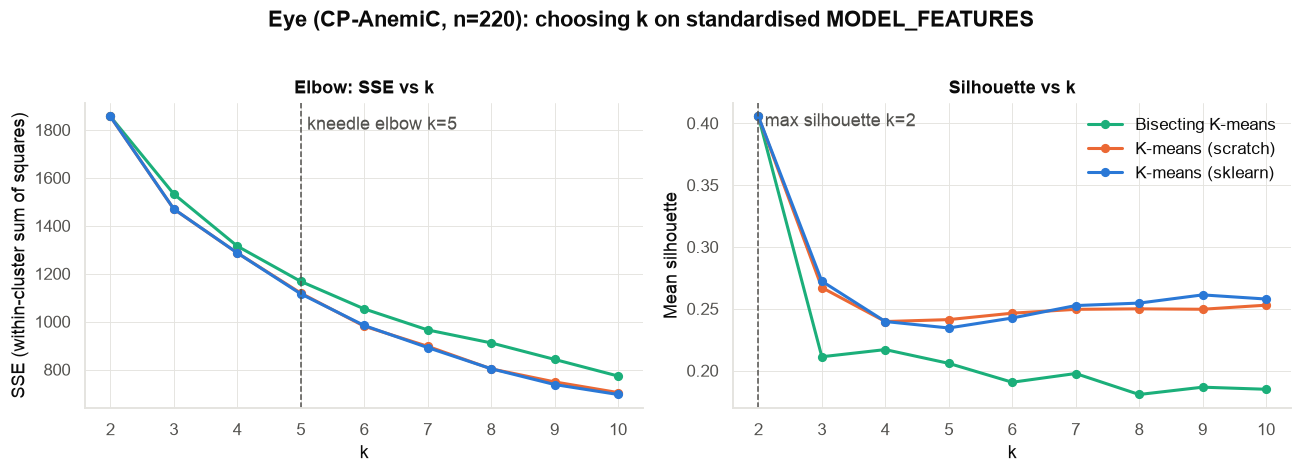

Elbow (kneedle) k = 5; silhouette-best k = 2  -> both reported; k = 5 saved for the app


sse                     silhouette                
kind bisecting   scratch   sklearn  bisecting scratch sklearn
k                                                            
2     1855.832  1855.832  1855.832      0.405   0.405   0.405
3     1532.279  1469.385  1469.669      0.211   0.267   0.272
4     1314.840  1286.518  1286.518      0.217   0.240   0.240
5     1167.685  1118.891  1115.735      0.206   0.241   0.234
6     1053.031   980.757   983.687      0.191   0.246   0.242
7      965.213   896.832   891.582      0.198   0.249   0.253
8      911.037   802.864   803.318      0.181   0.250   0.255
9      842.203   748.327   737.395      0.187   0.250   0.261
10     772.813   703.738   695.741      0.185   0.253   0.258

In [4]:
scan = C.k_scan(Z, KS, SEED)
sk = scan[scan.kind == "sklearn"]
k_elbow = C.elbow_k(sk.k, sk.sse)
k_sil = int(sk.loc[sk.silhouette.idxmax(), "k"])
K = k_elbow   # app / display model; k_sil is reported alongside

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for kind, g in scan.groupby("kind"):
    axes[0].plot(g.k, g.sse, marker="o", ms=5, lw=2, color=KIND_COLOUR[kind], label=KIND_LABEL[kind])
    axes[1].plot(g.k, g.silhouette, marker="o", ms=5, lw=2, color=KIND_COLOUR[kind], label=KIND_LABEL[kind])
axes[0].axvline(k_elbow, color=MUTED, ls="--", lw=1)
axes[0].text(k_elbow + 0.1, axes[0].get_ylim()[1] * 0.97, f"kneedle elbow k={k_elbow}", color=MUTED, va="top")
axes[1].axvline(k_sil, color=MUTED, ls="--", lw=1)
axes[1].text(k_sil + 0.1, axes[1].get_ylim()[1] * 0.98, f"max silhouette k={k_sil}", color=MUTED, va="top")
axes[0].set(xlabel="k", ylabel="SSE (within-cluster sum of squares)", title="Elbow: SSE vs k")
axes[1].set(xlabel="k", ylabel="Mean silhouette", title="Silhouette vs k")
axes[1].legend(frameon=False)
fig.suptitle("Eye (CP-AnemiC, n=220): choosing k on standardised MODEL_FEATURES", y=1.02, fontweight="bold")
fig.tight_layout()
save(fig, "01_eye_k_selection")

print(f"Elbow (kneedle) k = {k_elbow}; silhouette-best k = {k_sil}  -> both reported; k = {K} saved for the app")
scan.pivot(index="k", columns="kind", values=["sse", "silhouette"]).round(3)

**The two criteria disagree, which is itself a result.** Silhouette peaks sharply at k = 2 (0.41) and is flat at
~0.24–0.26 for every k ≥ 3, so it says "one clear split, then no strong structure". The SSE curve has no sharp bend; the
kneedle elbow (a label-free rule, fixed before looking at Hb) puts it at k = 5. Both solutions are analysed below; k = 5 is
saved as the app's pallor-group model because k = 2 only separates two exposure groups (Section 6), and silhouette cannot
discriminate among k ≥ 3. Both rules use the features only: Hb plays no part in choosing k.

## 3. Final eye clusters, named by centroid pallor

In [5]:
models, names, labels = {}, {}, {}
for k in sorted({k_sil, k_elbow}):
    m = C.pipeline(k, SEED).fit(eye[FEATS])
    models[k] = m
    names[k] = C.pallor_names(m["kmeans"].cluster_centers_, FEATS)
    labels[k] = m["kmeans"].labels_

for k in models:
    t = C.centroid_table(models[k], FEATS, names[k])
    d = eye.assign(c=labels[k]).groupby("c").agg(n=("hb", "size"), mean_hb=("hb", "mean"), pct_anaemic=("label", "mean"))
    t = t.merge(d, left_on="cluster", right_index=True)
    print(f"k = {k}   (redness_z = mean z of {C.REDNESS}; clusters ordered palest -> reddest)")
    display(t[["cluster", "name", "n", "mean_hb", "pct_anaemic", "redness_z", "lab_L_med", "lab_a_med",
               "erythema_index_med", "chrom_r_med", "R_med", "B_med"]].round(3))

k = 2   (redness_z = mean z of ['lab_a_med', 'erythema_index_med', 'chrom_r_med', 'lab_a_p10', 'erythema_index_p10']; clusters ordered palest -> reddest)


,cluster,name,n,mean_hb,pct_anaemic,redness_z,lab_L_med,lab_a_med,erythema_index_med,chrom_r_med,R_med,B_med
0,0,Pale,166,11.135,0.410,-0.407,65.908,23.148,0.164,0.435,209.81,129.455
1,1,Red,54,10.716,0.463,1.251,47.110,33.935,0.304,0.514,172.00,79.704


k = 5   (redness_z = mean z of ['lab_a_med', 'erythema_index_med', 'chrom_r_med', 'lab_a_p10', 'erythema_index_p10']; clusters ordered palest -> reddest)


,cluster,name,n,mean_hb,pct_anaemic,redness_z,lab_L_med,lab_a_med,erythema_index_med,chrom_r_med,R_med,B_med
0,1,Very pale,48,10.961,0.375,-0.856,67.835,20.010,0.134,0.407,206.365,149.698
1,3,Pale,58,10.670,0.569,-0.609,67.140,19.768,0.148,0.434,210.500,125.017
2,4,Intermediate,57,11.975,0.211,0.276,65.566,30.499,0.208,0.463,221.368,120.982
3,0,Pink,38,10.202,0.632,0.582,47.771,29.784,0.254,0.478,166.632,90.079
4,2,Red,19,11.153,0.316,2.030,41.152,36.724,0.377,0.570,160.632,54.632


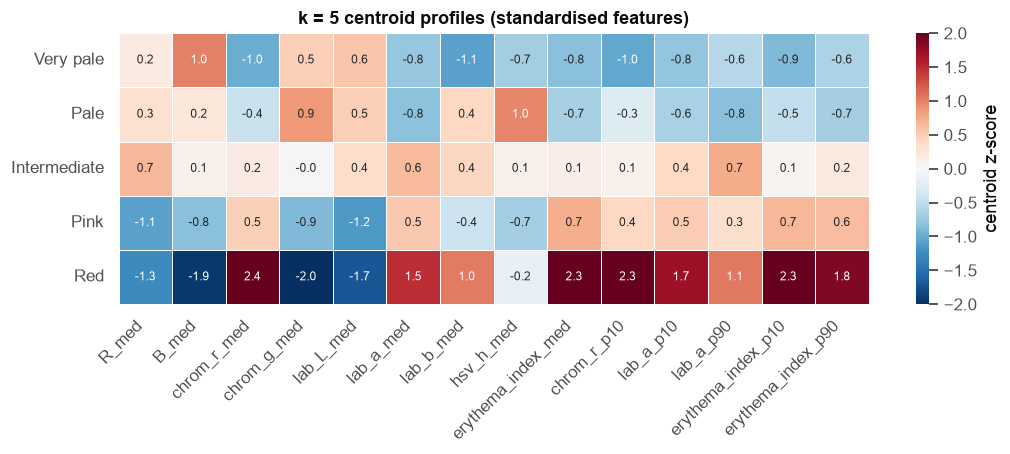

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.2))
k = K
cz = pd.DataFrame(models[k]["kmeans"].cluster_centers_, columns=FEATS)
order = C.pallor_order(models[k]["kmeans"].cluster_centers_, FEATS)
cz = cz.loc[order]
cz.index = [names[k][i] for i in order]
sns.heatmap(cz, cmap="RdBu_r", center=0, vmin=-2, vmax=2, annot=True, fmt=".1f", annot_kws={"size": 8},
            linewidths=0.5, linecolor="white", cbar_kws={"label": "centroid z-score"}, ax=ax)
ax.set_title(f"k = {k} centroid profiles (standardised features)")
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
save(fig, "02_eye_centroids")

## 4. Sorted proximity (distance) matrix

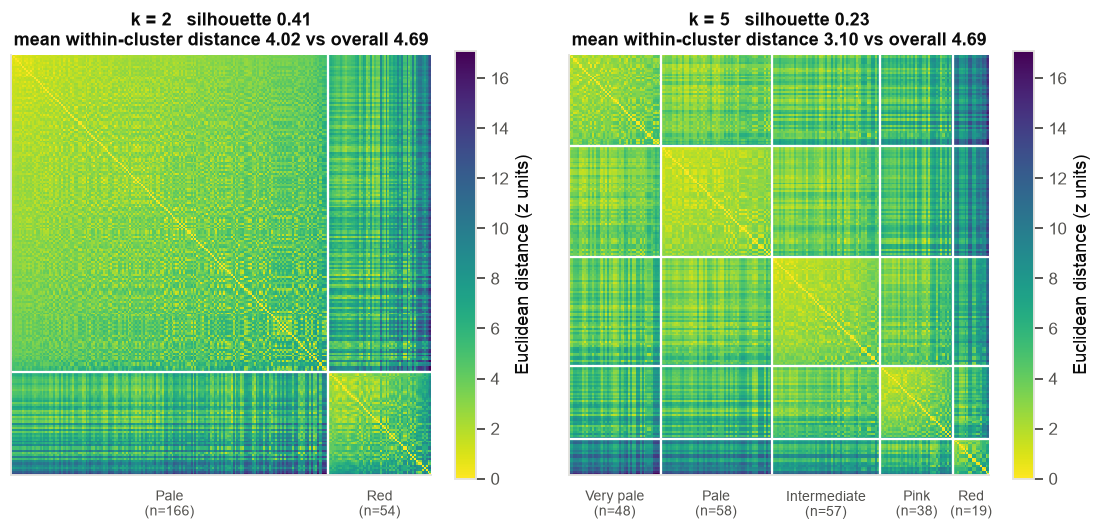

In [7]:
ks = sorted(models)
fig, axes = plt.subplots(1, len(ks), figsize=(6 * len(ks), 5.4))
for ax, k in zip(np.atleast_1d(axes), ks):
    order = C.pallor_order(models[k]["kmeans"].cluster_centers_, FEATS)
    D, lab = C.sorted_proximity(Z, labels[k], order)
    im = ax.imshow(D, cmap="viridis_r", interpolation="nearest")
    edges = np.flatnonzero(np.diff(lab)) + 0.5
    for e in edges:
        ax.axhline(e, color="white", lw=1.5)
        ax.axvline(e, color="white", lw=1.5)
    starts = np.r_[0, edges + 0.5]
    ends = np.r_[edges + 0.5, len(lab)]
    ax.set_xticks((starts + ends) / 2 - 0.5, [f"{names[k][c]}\n(n={int(e - s)})" for c, s, e in zip(order, starts, ends)],
                  fontsize=9)
    ax.set_yticks([])
    ax.grid(False)
    within = np.mean([D[np.ix_(lab == c, lab == c)].mean() for c in order])
    ax.set_title(f"k = {k}   silhouette {silhouette_score(Z, labels[k]):.2f}\nmean within-cluster distance "
                 f"{within:.2f} vs overall {D.mean():.2f}")
    fig.colorbar(im, ax=ax, fraction=0.046, label="Euclidean distance (z units)")
save(fig, "03_eye_proximity_matrix")

Points are sorted by cluster (palest first) and, within a cluster, by distance to the centroid. A good clustering
shows dark (small-distance) blocks on the diagonal and light off-diagonal blocks.

## 5. Supervised measures: purity and entropy against true Hb severity bands

In [8]:
majority = pd.Series(sev).value_counts(normalize=True).max()
H_sev = C.class_entropy(sev)
sup = []
for k in range(2, 7):
    lab = C.make_model("sklearn", k, SEED).fit(Z).labels_
    null = C.permutation_null(lab, sev, N_PERM, SEED)
    sup.append({"k": k, "purity": C.purity(lab, sev), "majority_baseline": majority,
                "purity_p": null["purity_p_value"], "entropy_bits": C.entropy(lab, sev),
                "entropy_null_mean": null["entropy_null_mean"], "entropy_p": null["entropy_p_value"],
                "ARI_severity": adjusted_rand_score(sev, lab), "purity_binary": C.purity(lab, eye.label),
                "kruskal_hb_p": kruskal(*[eye.hb[lab == c] for c in np.unique(lab)]).pvalue})
sup = pd.DataFrame(sup)
print(f"5 values of k tested: Bonferroni threshold 0.01")
print(f"Class entropy of the 4 severity bands (no clustering): {H_sev:.3f} bits; majority-class share {majority:.3f}")
sup.round(3)

5 values of k tested: Bonferroni threshold 0.01
Class entropy of the 4 severity bands (no clustering): 1.545 bits; majority-class share 0.577


,k,purity,majority_baseline,purity_p,entropy_bits,entropy_null_mean,entropy_p,ARI_severity,purity_binary,kruskal_hb_p
0,2,0.577,0.577,1.0,1.542,1.534,0.852,0.015,0.577,0.265
1,3,0.577,0.577,1.0,1.518,1.524,0.272,-0.017,0.577,0.298
2,4,0.577,0.577,1.0,1.493,1.513,0.099,-0.022,0.577,0.281
3,5,0.577,0.577,1.0,1.424,1.502,0.000,0.036,0.659,0.001
4,6,0.577,0.577,1.0,1.400,1.491,0.001,0.033,0.659,0.001


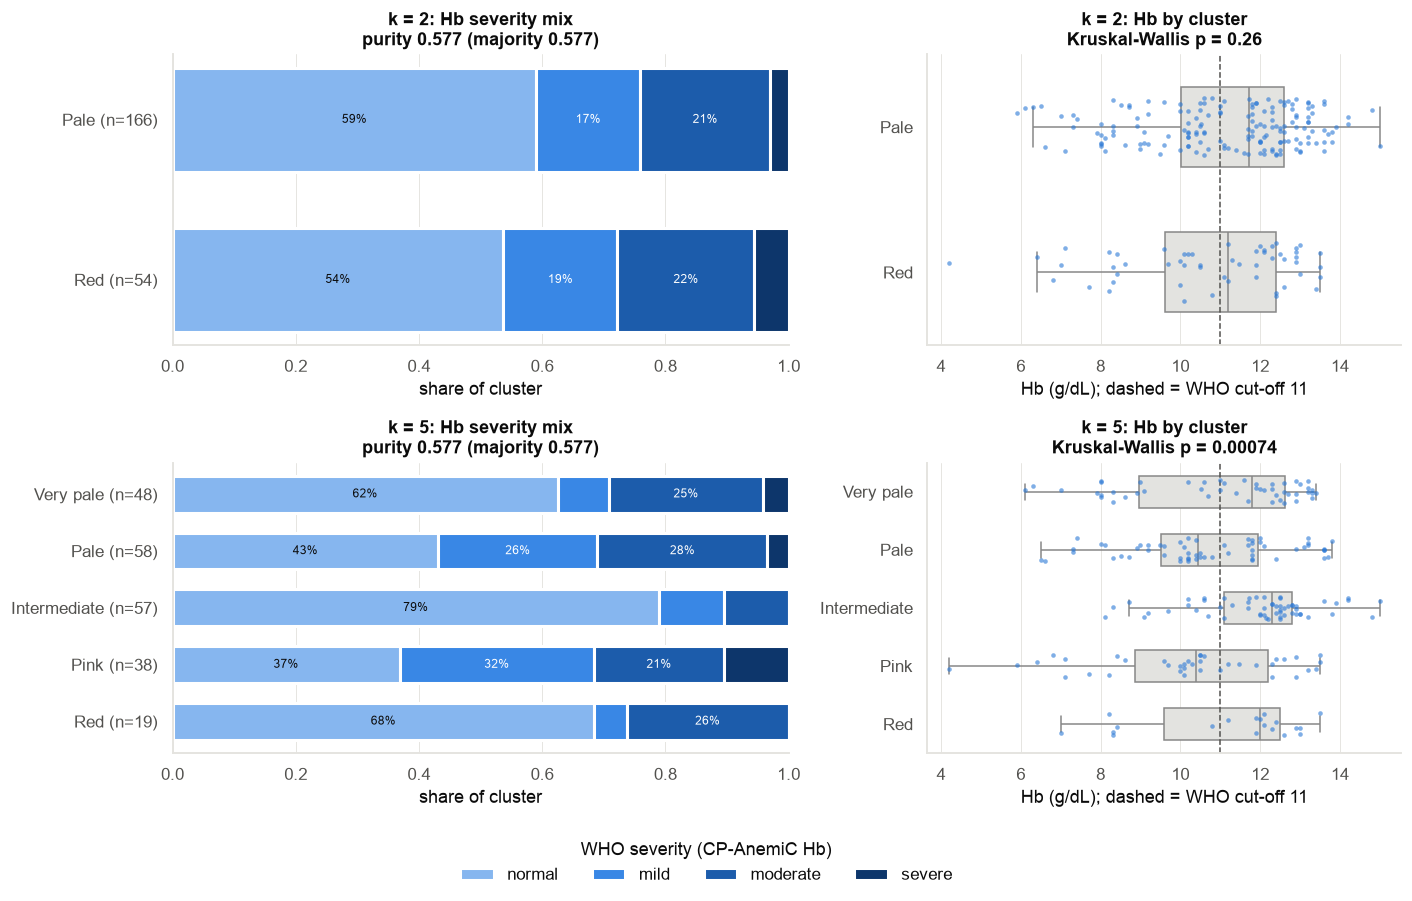

In [9]:
fig, axes = plt.subplots(len(ks), 2, figsize=(13, 3.2 + 2.2 * len(ks)), gridspec_kw={"width_ratios": [1.3, 1]})
axes = axes.ravel()
for j, k in enumerate(ks):
    order = C.pallor_order(models[k]["kmeans"].cluster_centers_, FEATS)
    tab = C.contingency(labels[k], sev, SEVERITIES).loc[order]
    frac = tab.div(tab.sum(axis=1), axis=0)
    ax = axes[2 * j]
    left = np.zeros(len(frac))
    ylab = [f"{names[k][c]} (n={tab.loc[c].sum()})" for c in order]
    for s in SEVERITIES:
        ax.barh(ylab, frac[s], left=left, color=SEV_COLOUR[s], edgecolor="white", linewidth=2, label=s, height=0.65)
        for y, (l, w) in enumerate(zip(left, frac[s])):
            if w > 0.12:
                ax.text(l + w / 2, y, f"{w:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if s != "normal" else INK)
        left += frac[s].to_numpy()
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of cluster")
    ax.set_title(f"k = {k}: Hb severity mix\npurity {C.purity(labels[k], sev):.3f} (majority {majority:.3f})")
    ax = axes[2 * j + 1]
    d = pd.DataFrame({"cluster": [names[k][c] for c in labels[k]], "hb": eye.hb})
    corder = [names[k][c] for c in order]
    sns.boxplot(d, x="hb", y="cluster", order=corder, color="#e4e3df", width=0.55, fliersize=0, ax=ax)
    sns.stripplot(d, x="hb", y="cluster", order=corder, color="#2a78d6", size=3, alpha=0.6, jitter=0.2, ax=ax)
    ax.axvline(11, color=MUTED, ls="--", lw=1)
    ax.set(ylabel="", xlabel="Hb (g/dL); dashed = WHO cut-off 11", title=f"k = {k}: Hb by cluster\nKruskal-Wallis p = "
           f"{kruskal(*[eye.hb[labels[k] == c] for c in order]).pvalue:.2g}")
fig.legend(*axes[0].get_legend_handles_labels(), ncol=4, frameon=False, loc="upper center",
           bbox_to_anchor=(0.5, 0.0), title="WHO severity (CP-AnemiC Hb)")
fig.tight_layout()
save(fig, "04_eye_purity_severity")

**Findings: purity and entropy.**
- **Purity cannot move here.** "normal" is the majority in every cluster at every k, so purity equals the majority
  baseline (0.577) for k = 2–6 (permutation p = 1). This is a known weakness of purity under class imbalance, not proof
  that the clusters are random.
- **Entropy does move.** At k = 2 the clusters carry no severity information (1.542 vs 1.545 bits, p = 0.85; Hb
  Kruskal–Wallis p = 0.27). From k = 5 the weighted entropy falls to 1.42 bits against a shuffled-label null of 1.50
  (p < 0.001), the Hb distributions differ (Kruskal–Wallis p = 0.0007, below the Bonferroni 0.01 for 5 values of k)
  and binary (anaemic / normal) purity rises to 0.659 from 0.577.
- **Where it comes from.** Two clusters of equal brightness (L\* ≈ 66–67) differ in redness: "Pale" (a\* 19.8,
  mean Hb 10.7, 57% anaemic) vs "Intermediate" (a\* 30.5, mean Hb 12.0, 21% anaemic). That is the pallor signal.
- **The effect is small.** ARI with the severity bands is 0.04 (0 = chance), and the pallor names do **not** rank Hb
  monotonically: the darker "Pink" cluster (L\* 48) has the lowest mean Hb (10.2). Under-exposed photos look redder
  in chromaticity, so raw redness mixes Hb with exposure.

**Is the k = 5 Hb association an artefact of one run?** K-means partitions at k = 5 are unstable (Section 7), so the
Kruskal–Wallis test is repeated over 20 seeds for sklearn and 10 for the scratch implementation.

In [10]:
rob = []
for kind, seeds in (("sklearn", range(SEED, SEED + 20)), ("scratch", range(SEED, SEED + 10))):
    for s in seeds:
        lab = C.make_model(kind, K, s).fit(Z).labels_
        rob.append({"kind": kind, "seed": s, "kruskal_hb_p": kruskal(*[eye.hb[lab == c] for c in np.unique(lab)]).pvalue,
                    "purity_binary": C.purity(lab, eye.label), "purity_severity": C.purity(lab, sev),
                    "ARI_vs_saved": adjusted_rand_score(lab, labels[K])})
rob = pd.DataFrame(rob)
robust_summary = rob.groupby("kind").agg(runs=("seed", "size"), kw_p_median=("kruskal_hb_p", "median"),
                                         kw_p_max=("kruskal_hb_p", "max"), purity_binary_min=("purity_binary", "min"),
                                         purity_binary_max=("purity_binary", "max"), ARI_vs_saved_min=("ARI_vs_saved", "min"))
robust_summary.round(4)

,runs,kw_p_median,kw_p_max,purity_binary_min,purity_binary_max,ARI_vs_saved_min
kind,,,,,,
scratch,10,0.0003,0.0018,0.6364,0.6727,0.6458
sklearn,20,0.0004,0.0025,0.6273,0.6682,0.6139


## 6. 2-D view (PCA, for display only)

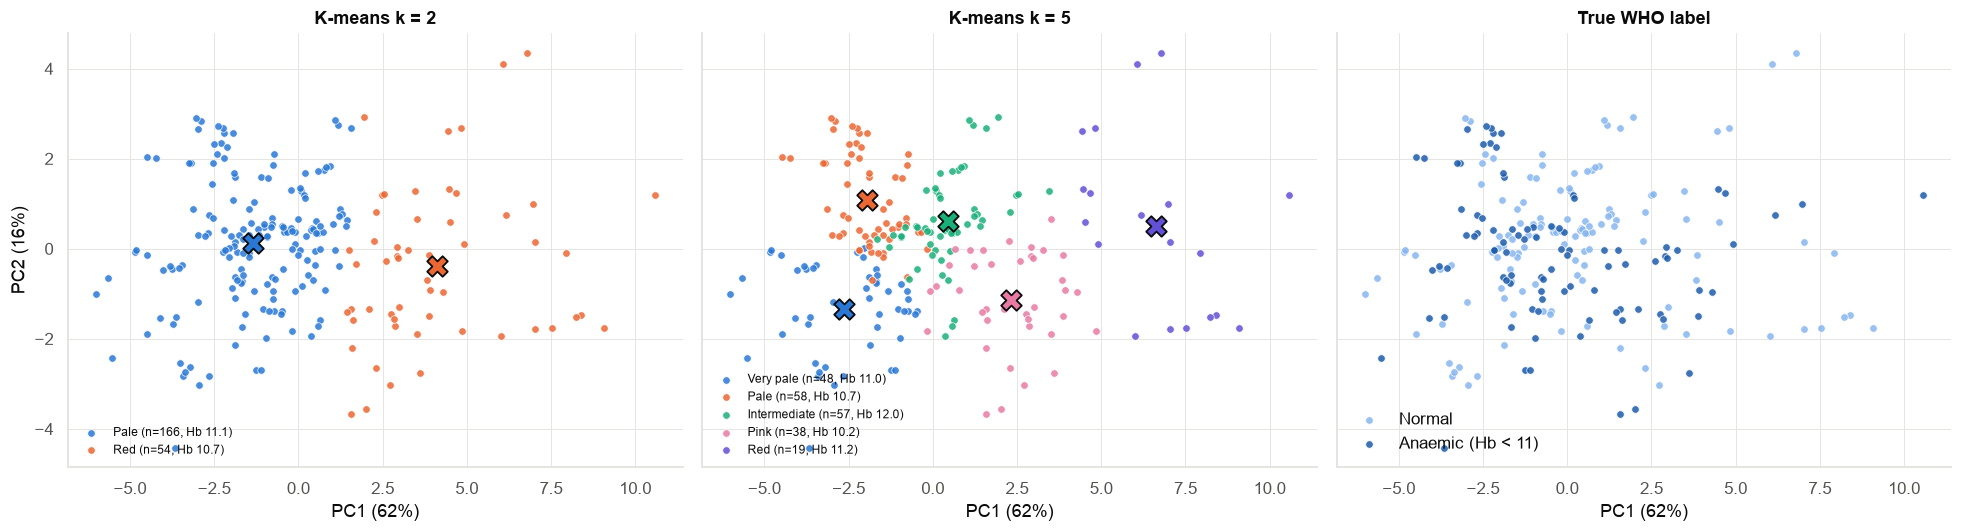

Corr of PC1 with lab_L_med / lab_a_med: [-0.8   0.82]


In [11]:
pca = PCA(2, random_state=SEED).fit(Z)
P = pca.transform(Z)
ks = sorted(models)
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(6 * (len(ks) + 1), 5), sharex=True, sharey=True)
for ax, k in zip(axes, ks):
    order = C.pallor_order(models[k]["kmeans"].cluster_centers_, FEATS)
    cent = pca.transform(models[k]["kmeans"].cluster_centers_)
    for i, c in enumerate(order):
        m = labels[k] == c
        ax.scatter(P[m, 0], P[m, 1], s=24, color=CLUSTER_COLOURS[i], edgecolor="white", lw=0.5, alpha=0.85,
                   label=f"{names[k][c]} (n={m.sum()}, Hb {eye.hb[m].mean():.1f})")
        ax.scatter(*cent[c], marker="X", s=180, color=CLUSTER_COLOURS[i], edgecolor=INK, lw=1.2)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    ax.set_title(f"K-means k = {k}")
for lab_, name, col in ((0, "Normal", "#86b6ef"), (1, "Anaemic (Hb < 11)", "#1c5cab")):
    m = eye.label == lab_
    axes[-1].scatter(P[m, 0], P[m, 1], s=24, color=col, edgecolor="white", lw=0.5, alpha=0.85, label=name)
axes[-1].legend(frameon=False, loc="lower left")
axes[-1].set_title("True WHO label")
ev = pca.explained_variance_ratio_
for ax in axes:
    ax.set_xlabel(f"PC1 ({100 * ev[0]:.0f}%)")
axes[0].set_ylabel(f"PC2 ({100 * ev[1]:.0f}%)")
fig.tight_layout()
save(fig, "05_eye_pca_clusters")
print("Corr of PC1 with lab_L_med / lab_a_med:",
      np.round([np.corrcoef(P[:, 0], eye[f])[0, 1] for f in ("lab_L_med", "lab_a_med")], 2))

**Findings: what K-means found.** PC1 (62% of variance) correlates −0.80 with L\* and +0.82 with a\*: the dominant axis is
"dark and red" versus "bright and pale", and it is mostly exposure. The k = 2 split (silhouette 0.41) cuts along this
axis and carries no Hb information. The anaemic and normal children overlap completely in this plane.

## 7. K-means strengths and weaknesses, measured on our data

In [12]:
stability = pd.DataFrame({f"k={k}": C.init_stability(Z, k, range(SEED, SEED + 30)) for k in (2, 3, 4, 5)}).T
print("(a) Initialisation sensitivity: 30 single-init (n_init=1, k-means++) runs")
display(stability.round(3))

raw_lab = cluster.KMeans(K, n_init=10, random_state=SEED).fit_predict(eye[FEATS])
dominant = eye[FEATS].var().sort_values(ascending=False)
print(f"(b) Scaling: unscaled K-means vs scaled, ARI = {adjusted_rand_score(raw_lab, labels[K]):.3f}; "
      f"unscaled variance is dominated by {dominant.index[0]} ({dominant.iloc[0] / dominant.sum():.0%}) and "
      f"{dominant.index[1]} ({dominant.iloc[1] / dominant.sum():.0%})")

out = (np.abs(Z) > 3).any(axis=1)
lab_wo = cluster.KMeans(K, n_init=10, random_state=SEED).fit(Z[~out]).predict(Z)
print(f"(c) Outliers: {out.sum()} children have some |z| > 3; refitting without them changes the partition "
      f"(ARI with full fit = {adjusted_rand_score(lab_wo, labels[K]):.3f})")
for k in (4, K):
    sizes = np.bincount(C.make_model("sklearn", k, SEED).fit(Z).labels_)
    print(f"    cluster sizes at k={k}: {sorted(sizes.tolist())}")

bis = scan.pivot(index="k", columns="kind", values="sse")
print(f"(d) Bisecting vs standard K-means SSE ratio, k=3..6: {(bis.bisecting / bis.sklearn).loc[3:6].round(3).tolist()}")

rho = eye[FEATS].corr("spearman").abs()
redfam = [f for f in FEATS if f.startswith(("lab_a", "erythema", "chrom_r"))]
print(f"(e) Correlated features: {len(redfam)} of {len(FEATS)} features are redness measures; mean |rho| among them "
      f"{rho.loc[redfam, redfam].values[np.triu_indices(len(redfam), 1)].mean():.2f}, so Euclidean distance counts "
      f"redness several times")

(a) Initialisation sensitivity: 30 single-init (n_init=1, k-means++) runs


,sse_min,sse_max,sse_rel_spread,ari_mean,ari_min
k=2,1855.832,1857.352,0.001,0.951,0.888
k=3,1469.385,1550.842,0.055,0.718,0.261
k=4,1289.113,1354.775,0.051,0.460,0.203
k=5,1112.978,1223.778,0.100,0.477,0.150


(b) Scaling: unscaled K-means vs scaled, ARI = 0.247; unscaled variance is dominated by B_med (42%) and R_med (39%)
(c) Outliers: 11 children have some |z| > 3; refitting without them changes the partition (ARI with full fit = 0.618)
    cluster sizes at k=4: [23, 28, 67, 102]
    cluster sizes at k=5: [19, 38, 48, 57, 58]
(d) Bisecting vs standard K-means SSE ratio, k=3..6: [1.043, 1.022, 1.047, 1.07]
(e) Correlated features: 8 of 14 features are redness measures; mean |rho| among them 0.79, so Euclidean distance counts redness several times


**K-means strengths and weaknesses, as seen in this data**

| | Evidence here |
|---|---|
| ✔ Simple, fast, verifiable | Our NumPy version gives the same SSE as sklearn at k = 2 and 4 (ARI 1.0) and a monotonically falling SSE per Lloyd iteration; 30 fits take seconds. |
| ✔ Interpretable centroids | Each cluster is a mean colour profile that can be named ("Pale", "Red") and shown in the app. |
| ✔ Finds the dominant structure | It recovers the exposure/redness axis (PC1) with no labels. |
| ✘ k must be chosen, and criteria disagree | Silhouette says 2, the elbow says 5, and the SSE curve has no sharp bend. |
| ✘ Sensitive to initialisation | With single k-means++ starts the SSE varies up to 10% at k = 5, and runs agree only at ARI ≈ 0.48 (min 0.15). At k = 3 and 5, sklearn and scratch with n_init = 10 reach different local optima (ARI 0.89, 0.68). k = 2 is stable (ARI 0.95). |
| ✘ Scale dependent | Without standardisation, B_med and R_med hold 81% of the variance and the partition changes (ARI 0.25 with the scaled one). |
| ✘ Sensitive to outliers | 11 children have a feature with \|z\| > 3; 9 of them sit in the 19-child "Red" cluster (47% of it), and refitting without them changes the k = 5 partition (ARI 0.62). |
| ✘ Assumes round, equal-variance clusters and counts correlated features many times | 8 of 14 features are redness measures (mean \|ρ\| 0.79), so Euclidean distance weights redness about 8×; the data form one continuous cloud, not separated blobs (silhouette ≤ 0.27 for k ≥ 3). |
| ✘ Unsupervised = finds variance, not the target | The largest colour variance is lighting, not Hb. The Hb signal appears only in the finer k = 5 split, and weakly. |
| Bisecting K-means | Greedy top-down splits with no global refinement: SSE is 2–7% higher than standard K-means for k = 3–6, and silhouette is lower. In exchange it gives a nested hierarchy and is cheaper for large k. |

## 8. Palm and nail (Ghana, folder labels)

Same procedure on the Ghana palm and fingernail originals. Labels are **folder labels** (from file names, no Hb, ~3%
label noise), so only a binary anaemic / normal yardstick exists. Duplicate re-crops share a `cv_group`; one row per
group is kept so a child photographed twice is not counted twice.

palm: n=501  elbow k=5  silhouette k=2


,2,5
purity,0.575,0.611
majority_baseline,0.575,0.575
purity_p_value,1.000,0.001
entropy_bits,0.976,0.923
class_entropy_bits,0.984,0.984
entropy_p_value,0.032,0.000
ARI,0.009,0.028
silhouette,0.363,0.267


nail: n=514  elbow k=5  silhouette k=2


,2,5
purity,0.582,0.582
majority_baseline,0.582,0.582
purity_p_value,1.000,1.000
entropy_bits,0.981,0.972
class_entropy_bits,0.981,0.981
entropy_p_value,1.000,0.207
ARI,-0.002,-0.002
silhouette,0.350,0.262


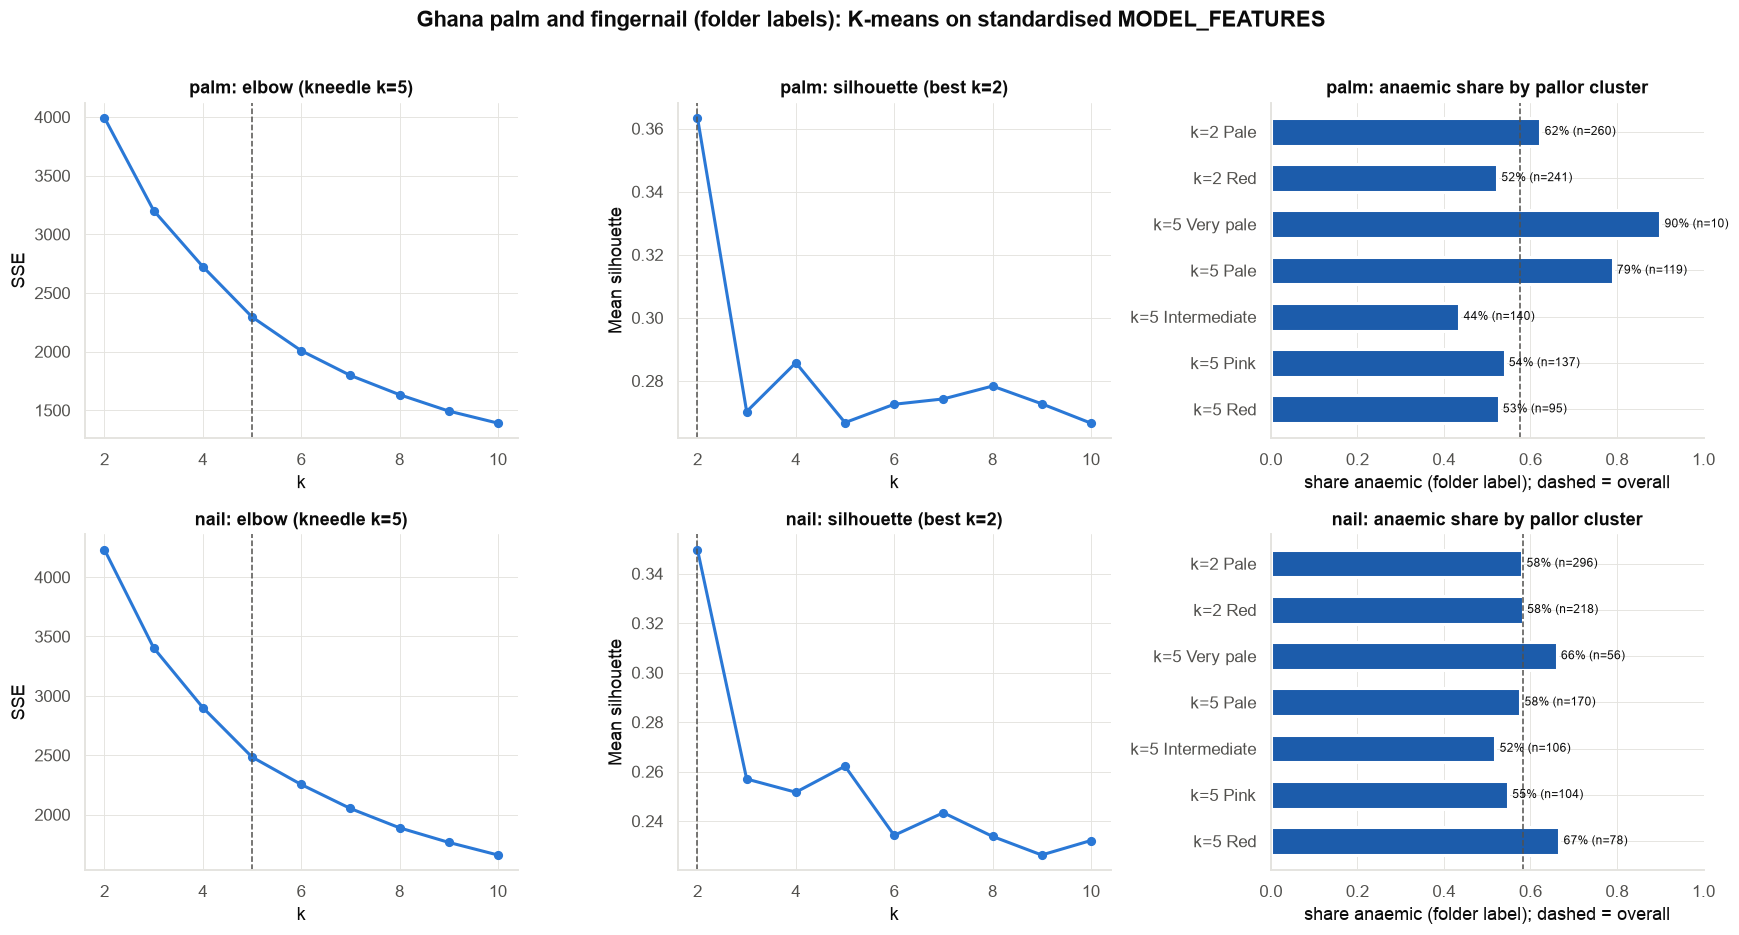

In [13]:
site_res = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
for row, site in enumerate(("palm", "nail")):
    d = pd.read_csv(config.GHANA_SITES[site]["csv"]).drop_duplicates("cv_group").reset_index(drop=True)
    Zs = StandardScaler().fit_transform(d[FEATS])
    y = np.where(d.label == 1, "Anaemic", "Normal")
    sc = C.k_scan(Zs, KS, SEED, kinds=("sklearn", "scratch"))
    s = sc[sc.kind == "sklearn"]
    ke, ksil = C.elbow_k(s.k, s.sse), int(s.loc[s.silhouette.idxmax(), "k"])
    ax = axes[row, 0]
    ax.plot(s.k, s.sse, marker="o", ms=5, lw=2, color=KIND_COLOUR["sklearn"])
    ax.axvline(ke, color=MUTED, ls="--", lw=1)
    ax.set(xlabel="k", ylabel="SSE", title=f"{site}: elbow (kneedle k={ke})")
    ax = axes[row, 1]
    ax.plot(s.k, s.silhouette, marker="o", ms=5, lw=2, color=KIND_COLOUR["sklearn"])
    ax.axvline(ksil, color=MUTED, ls="--", lw=1)
    ax.set(xlabel="k", ylabel="Mean silhouette", title=f"{site}: silhouette (best k={ksil})")

    res = {"n": len(d), "anaemic_share": float(d.label.mean()), "k_elbow": ke, "k_silhouette": ksil,
           "scan": sc.to_dict("records"), "by_k": {}}
    maj = max(d.label.mean(), 1 - d.label.mean())
    bars = []
    for k in sorted({ksil, ke}):
        m = C.pipeline(k, SEED).fit(d[FEATS])
        lab = m["kmeans"].labels_
        nm = C.pallor_names(m["kmeans"].cluster_centers_, FEATS)
        order = C.pallor_order(m["kmeans"].cluster_centers_, FEATS)
        null = C.permutation_null(lab, y, N_PERM, SEED)
        tab = C.contingency(lab, y, ["Normal", "Anaemic"]).loc[order]
        res["by_k"][k] = {"purity": C.purity(lab, y), "majority_baseline": maj, "entropy_bits": C.entropy(lab, y),
                          "class_entropy_bits": C.class_entropy(y), "silhouette": float(silhouette_score(Zs, lab)),
                          "ARI": adjusted_rand_score(y, lab), **null,
                          "clusters": [{"name": nm[c], "n": int(tab.loc[c].sum()),
                                        "pct_anaemic": float(tab.loc[c, "Anaemic"] / tab.loc[c].sum())} for c in order]}
        bars += [(f"k={k} {nm[c]}", tab.loc[c, "Anaemic"] / tab.loc[c].sum(), tab.loc[c].sum()) for c in order]
    ax = axes[row, 2]
    yl = [b[0] for b in bars]
    ax.barh(yl, [b[1] for b in bars], color=FOLDER_COLOUR["Anaemic"], height=0.6, edgecolor="white", linewidth=2)
    for i, b in enumerate(bars):
        ax.text(b[1] + 0.01, i, f"{b[1]:.0%} (n={b[2]})", va="center", fontsize=8, color=INK)
    ax.axvline(d.label.mean(), color=MUTED, ls="--", lw=1)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set(xlabel="share anaemic (folder label); dashed = overall", title=f"{site}: anaemic share by pallor cluster")
    site_res[site] = res
    print(f"{site}: n={len(d)}  elbow k={ke}  silhouette k={ksil}")
    display(pd.DataFrame({k: {m_: v[m_] for m_ in ("purity", "majority_baseline", "purity_p_value", "entropy_bits",
                                                   "class_entropy_bits", "entropy_p_value", "ARI", "silhouette")}
                          for k, v in res["by_k"].items()}).round(3))
fig.suptitle("Ghana palm and fingernail (folder labels): K-means on standardised MODEL_FEATURES", y=1.01,
             fontweight="bold")
fig.tight_layout()
save(fig, "06_palm_nail")

**Findings: palm and nail (folder labels).** The same structure appears at both sites: silhouette is best at k = 2, the
elbow at k = 5, and k = 2 is unrelated to the label (purity = majority baseline).
- **Palm, k = 5:** the clusters follow pallor. "Very pale" is 90% anaemic (n = 10) and "Pale" 79% (n = 119), against
  44–54% for the redder clusters. Purity is 0.611 vs 0.575 (p = 0.001) and entropy 0.923 vs 0.984 bits (p < 0.001).
  Caveat: the pale palm clusters are also cooler (lower b\*), and "Very pale" (b\* < 0) looks like a white-balance
  outlier group, so capture differences cannot be ruled out.
- **Nail:** no association at any k (k = 5 purity = majority baseline, entropy p = 0.21).
- These are folder labels (~3% label noise, children ≤ 5 y), so they are weaker evidence than the eye Hb results.

## 9. Save the cluster model and results for the app

In [14]:
order = C.pallor_order(models[K]["kmeans"].cluster_centers_, FEATS)
centroids = C.centroid_table(models[K], FEATS, names[K])
joblib.dump({"model": models[K], "features": FEATS, "k": K, "names": names[K],
             "pallor_order": order.tolist(), "centroids": centroids,
             "alt_models": {k: {"model": models[k], "names": names[k]} for k in models if k != K}}, config.OUT_DIR / "models" / "clusters_eye.joblib")

def cluster_summary(k):
    o = C.pallor_order(models[k]["kmeans"].cluster_centers_, FEATS)
    tab = C.contingency(labels[k], sev, SEVERITIES)
    return [{"cluster": int(c), "name": names[k][c], "n": int(tab.loc[c].sum()),
             "mean_hb": float(eye.hb[labels[k] == c].mean()),
             "pct_anaemic": float(eye.label[labels[k] == c].mean()),
             "severity_counts": {s: int(tab.loc[c, s]) for s in tab.columns},
             "centroid": dict(zip(FEATS, models[k]["scale"].inverse_transform(
                 models[k]["kmeans"].cluster_centers_[[c]])[0].round(4).tolist()))} for c in o]

RESULTS.update({
    "eye": {
        "data": "CP-AnemiC primary (conjunctiva), Hb labels", "n": len(eye),
        "k_elbow": k_elbow, "k_silhouette": k_sil, "k_chosen": K,
        "k_rule": "kneedle elbow saved for the app; silhouette peaks at k=2 then is flat for k>=3",
        "scan": scan.to_dict("records"), "scratch_check": scratch_check.to_dict("records"),
        "supervised": sup.to_dict("records"), "class_entropy_bits": H_sev, "majority_baseline": majority,
        "clusters": {str(k): cluster_summary(k) for k in models},
        "init_stability": stability.to_dict("index"),
        "scaling_ari_unscaled_vs_scaled": adjusted_rand_score(raw_lab, labels[K]),
        "k5_robustness": robust_summary.reset_index().to_dict("records"),
    },
    "palm": {"labels": "folder (file name)", **site_res["palm"]},
    "nail": {"labels": "folder (file name)", **site_res["nail"]},
    "model_path": "outputs/models/clusters_eye.joblib",
    "figures": sorted(str(p.relative_to(config.OUT_DIR.parent)) for p in FIG_DIR.glob("*.png")),
})
(config.OUT_DIR / "results" / "clustering.json").write_text(json.dumps(RESULTS, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("saved", config.OUT_DIR / "results" / "clustering.json")

saved /Users/nikitha/projects/netra-hb/outputs/results/clustering.json


## Key findings

1. **The two rules for k disagree.** Silhouette picks k = 2 (0.41), then is flat (~0.25) for k ≥ 3. The kneedle elbow
   picks k = 5. The colour features form one continuous cloud with one dominant axis, not well-separated groups.
2. **The strongest cluster structure is exposure, not anaemia.** The k = 2 split follows PC1 (L\* vs a\*, 62% of
   variance) and has no Hb information: purity equals the majority baseline 0.577, entropy 1.542 vs 1.545 bits, and
   Hb Kruskal–Wallis p = 0.27.
3. **A weak pallor signal appears at k = 5.** At equal brightness, the paler cluster has mean Hb 10.7 (57% anaemic) and
   the redder one 12.0 (21%). Entropy falls to 1.42 bits (null 1.50, p < 0.001), Hb Kruskal–Wallis p = 0.0007, and
   binary purity rises to 0.66. The Hb difference holds across 30 reruns (20 sklearn, 10 scratch; every
   p < 0.003), even though the partitions themselves are only moderately stable. ARI with the severity bands is only
   0.04, so the clusters are useful as "pallor groups" in the app, not as a screening rule.
4. **Purity misleads under class imbalance.** "normal" is the majority in every cluster, so severity purity stays at
   0.577 for every k. Entropy, the shuffled-label null and Hb tests are the informative supervised measures.
5. **Sites:** palm (folder labels) shows the clearest pallor gradient at k = 5 (79–90% anaemic in the pale clusters
   vs ~50% elsewhere; purity 0.611 vs 0.575, p = 0.001), with a possible white-balance confound. The fingernail clusters show no association.
6. **K-means weaknesses seen here:** the choice of k, initialisation (SSE spread up to 10% and ARI ≈ 0.5 between
   single-start runs at k = 5), scaling (ARI 0.25 unscaled vs scaled), outliers (9 of 11 extreme children make up half of the 19-child "Red" cluster), and
   correlated redness features weighted about 8× in the distance. The scratch K-means reaches sklearn's SSE (it is
   identical at k = 2 and 4).

Saved: `outputs/models/clusters_eye.joblib` (scaler + K-means k = 5, pallor names, centroids; the k = 2 model is under
`alt_models`) and `outputs/results/clustering.json`.